# Week 10 — Decision Trees and Overfitting

## Objective

Evaluate a Decision Tree classifier for next-day
KSI collision risk ranking at signalized intersections.

The experiment uses the Week 9 feature dataset
and the existing temporal validation strategy.

## Research Questions

- Can Decision Trees outperform Logistic Regression?
- How does tree depth affect generalization?
- Does increasing model complexity lead to overfitting?
- Which features contribute most to tree splits?

## Evaluation Strategy

- Temporal cross-validation
- Average Precision (AP)
- Train-validation generalization gap
- Comparison with previous baselines

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/processed/intersection_day_2018_features.csv",
    parse_dates=["prediction_date", "target_date"]
)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["target"].value_counts())
print("\nColumns:")
print(df.columns.tolist())

Matplotlib is building the font cache; this may take a moment.


Dataset shape: (823217, 16)

Target distribution:
target
0    823098
1       119
Name: count, dtype: int64

Columns:
['intersection_id', 'prediction_date', 'target_date', 'historical_ksi_count', 'historical_traffic_volume', 'day_of_week', 'month', 'target', 'ksi_count_30d', 'ksi_count_365d', 'is_weekend', 'traffic_missing', 'weather_date', 'temperature_prev_day', 'precipitation_prev_day', 'weather_missing']


In [3]:
numerical_features = [
    "historical_ksi_count",
    "historical_traffic_volume",
    "ksi_count_30d",
    "ksi_count_365d",
    "temperature_prev_day",
    "precipitation_prev_day"
]

categorical_features = [
    "day_of_week",
    "month"
]

binary_features = [
    "is_weekend",
    "traffic_missing",
    "weather_missing"
]

features = numerical_features + categorical_features + binary_features

X = df[features].copy()
y = df["target"].copy()

In [4]:
train_mask = df["prediction_date"] <= pd.Timestamp("2018-09-29")
val_mask = df["prediction_date"] >= pd.Timestamp("2018-10-01")

X_train = X.loc[train_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)

X_val = X.loc[val_mask].reset_index(drop=True)
y_val = y.loc[val_mask].reset_index(drop=True)

train_dates = df.loc[train_mask, "prediction_date"].reset_index(drop=True)

split_summary = pd.DataFrame({
    "samples": [len(X_train), len(X_val)],
    "positives": [y_train.sum(), y_val.sum()],
    "positive_rate": [y_train.mean(), y_val.mean()]
}, index=["Train", "Validation"])

split_summary

,samples,positives,positive_rate
Train,613223,81,0.000132
Validation,207736,38,0.000183


In [5]:
from sklearn.model_selection import TimeSeriesSplit

unique_dates = np.sort(train_dates.unique())

tscv = TimeSeriesSplit(n_splits=3, gap=1)

cv_splits = []
fold_summary = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(unique_dates), start=1
):
    fold_train_dates = unique_dates[train_idx]
    fold_val_dates = unique_dates[val_idx]

    train_rows = np.flatnonzero(
        train_dates.isin(fold_train_dates)
    )

    val_rows = np.flatnonzero(
        train_dates.isin(fold_val_dates)
    )

    cv_splits.append((train_rows, val_rows))

    fold_summary.append({
        "fold": fold,
        "train_end": fold_train_dates[-1],
        "val_start": fold_val_dates[0],
        "val_end": fold_val_dates[-1],
        "train_positives": y_train.iloc[train_rows].sum(),
        "val_positives": y_train.iloc[val_rows].sum()
    })

pd.DataFrame(fold_summary)

,fold,train_end,val_start,val_end,train_positives,val_positives
0,1,2018-03-08,2018-03-10,2018-05-16,14,20
1,2,2018-05-15,2018-05-17,2018-07-23,34,18
2,3,2018-07-22,2018-07-24,2018-09-29,51,29


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        random_state=42
    ))
])

tree_pipeline.fit(X_train, y_train)

train_proba = tree_pipeline.predict_proba(X_train)[:, 1]

train_ap = average_precision_score(y_train, train_proba)

print(f"Train Average Precision: {train_ap:.6f}")

Train Average Precision: 0.000926


In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_depth": [1, 2, 3, 5, None]
}

grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv_splits,
    return_train_score=True,
    refit=True,
    n_jobs=1
)

grid_search.fit(X_train, y_train)

depth_results = pd.DataFrame(grid_search.cv_results_)[[
    "param_model__max_depth",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

depth_results.columns = [
    "max_depth",
    "train_ap",
    "cv_ap",
    "cv_std",
    "rank"
]

depth_results["generalization_gap"] = (
    depth_results["train_ap"] - depth_results["cv_ap"]
)

print("Best parameters:", grid_search.best_params_)
print(f"Best CV AP: {grid_search.best_score_:.6f}")

depth_results

Best parameters: {'model__max_depth': 3}
Best CV AP: 0.000219


,max_depth,train_ap,cv_ap,cv_std,rank,generalization_gap
0,1,0.000159,0.000152,0.000040,4,0.000007
1,2,0.000343,0.000213,0.000049,2,0.000131
2,3,0.002095,0.000219,0.000074,1,0.001876
3,5,0.108730,0.000199,0.000083,3,0.108531
4,None,0.750683,0.000146,0.000031,5,0.750538


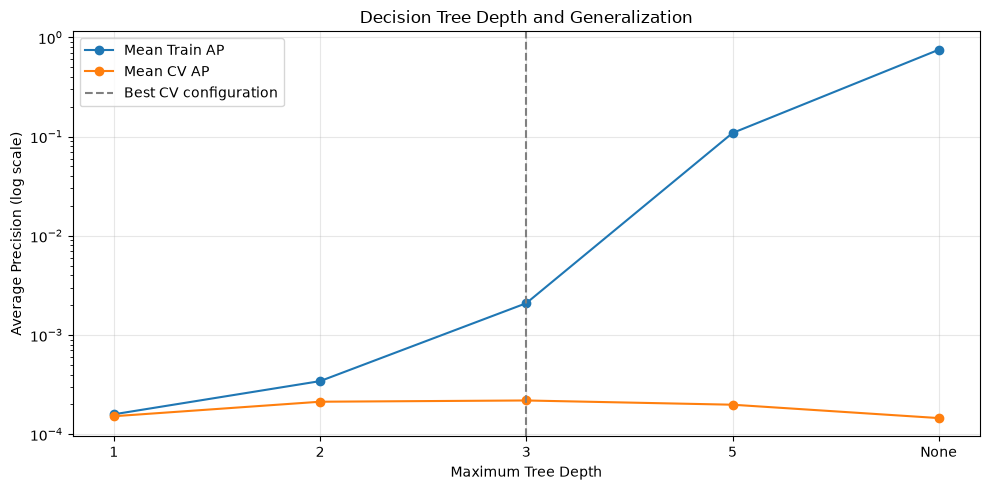

In [9]:
depth_labels = depth_results["max_depth"].map(
    lambda depth: "None" if pd.isna(depth) else str(int(depth))
)

plt.figure(figsize=(10, 5))

plt.plot(
    depth_labels,
    depth_results["train_ap"],
    marker="o",
    label="Mean Train AP"
)

plt.plot(
    depth_labels,
    depth_results["cv_ap"],
    marker="o",
    label="Mean CV AP"
)

plt.axvline(
    x=depth_labels.iloc[grid_search.best_index_],
    linestyle="--",
    color="gray",
    label="Best CV configuration"
)

plt.yscale("log")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Average Precision (log scale)")
plt.title("Decision Tree Depth and Generalization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
best_tree = grid_search.best_estimator_

train_proba = best_tree.predict_proba(X_train)[:, 1]
val_proba = best_tree.predict_proba(X_val)[:, 1]

tree_train_ap = average_precision_score(y_train, train_proba)
tree_cv_ap = grid_search.best_score_
tree_val_ap = average_precision_score(y_val, val_proba)

tree_evaluation = pd.DataFrame({
    "dataset": [
        "Train",
        "Temporal CV",
        "Development Validation"
    ],
    "average_precision": [
        tree_train_ap,
        tree_cv_ap,
        tree_val_ap
    ]
})

print("Selected parameters:", grid_search.best_params_)
print(f"Validation positive rate: {y_val.mean():.6f}")
print(f"Train-Validation Gap: {tree_train_ap - tree_val_ap:.6f}")

tree_evaluation

Selected parameters: {'model__max_depth': 3}
Validation positive rate: 0.000183
Train-Validation Gap: 0.000684


,dataset,average_precision
0,Train,0.000926
1,Temporal CV,0.000219
2,Development Validation,0.000242


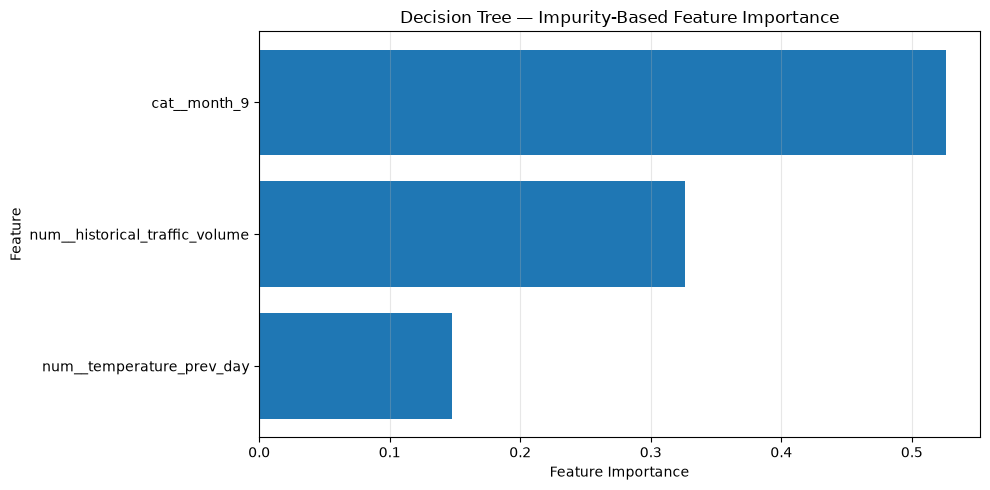

,feature,importance
0,cat__month_9,0.525919
1,num__historical_traffic_volume,0.326171
2,num__temperature_prev_day,0.147910


In [11]:
fitted_preprocessor = best_tree.named_steps["preprocessor"]
fitted_model = best_tree.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_model.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

important_features = importance_df[
    importance_df["importance"] > 0
].copy()

plt.figure(figsize=(10, 5))

plt.barh(
    important_features["feature"],
    important_features["importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Decision Tree — Impurity-Based Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

important_features

In [12]:
experiment_results = pd.DataFrame([
    {
        "model": "Historical Baseline W6",
        "features": "Historical frequency",
        "configuration": "Historical mean",
        "cv_ap": 0.000173,
        "val_ap": 0.000182
    },
    {
        "model": "Logistic Regression W5",
        "features": "4 features",
        "configuration": "C=1.0",
        "cv_ap": 0.000626,
        "val_ap": 0.000372
    },
    {
        "model": "Logistic Regression W7",
        "features": "4 features",
        "configuration": "C=0.1",
        "cv_ap": 0.000629,
        "val_ap": 0.000372
    },
    {
        "model": "Logistic Regression W9",
        "features": "11 features",
        "configuration": "C=0.1",
        "cv_ap": 0.000976,
        "val_ap": 0.000389
    },
    {
        "model": "Decision Tree W10",
        "features": f"{len(features)} features",
        "configuration": (
            f"max_depth={grid_search.best_params_['model__max_depth']}"
        ),
        "cv_ap": tree_cv_ap,
        "val_ap": tree_val_ap
    }
])

experiment_results["cv_rank"] = (
    experiment_results["cv_ap"]
    .rank(ascending=False, method="min")
    .astype(int)
)

experiment_results

,model,features,configuration,cv_ap,val_ap,cv_rank
0,Historical Baseline W6,Historical frequency,Historical mean,0.000173,0.000182,5
1,Logistic Regression W5,4 features,C=1.0,0.000626,0.000372,3
2,Logistic Regression W7,4 features,C=0.1,0.000629,0.000372,2
3,Logistic Regression W9,11 features,C=0.1,0.000976,0.000389,1
4,Decision Tree W10,11 features,max_depth=3,0.000219,0.000242,4


## Conclusions

### Model Selection

Five Decision Tree depth configurations were
evaluated using three temporal cross-validation
folds.

The selected configuration was:

- Criterion: Gini
- Maximum depth: 3
- Random state: 42
- Input features: 11

### Model Performance

- Train AP: 0.000926
- Mean temporal CV AP: 0.000219
- Development validation AP: 0.000242
- Train-validation gap: 0.000684

### Overfitting

Increasing tree depth substantially improved
training performance without improving
temporal validation performance.

The unrestricted tree achieved a mean training
AP of 0.750683, while its mean CV AP decreased
to 0.000146.

This indicates severe overfitting in the
unrestricted tree.

Depth 3 achieved the highest mean CV AP,
although its advantage over depth 2 was small
relative to the variation across folds.

### Feature Importance

The selected tree assigned non-zero
impurity-based importance to three transformed
features:

- September indicator: 52.59%
- Historical traffic volume: 32.62%
- Previous-day temperature: 14.79%

The strong reliance on the September indicator
raises concerns about temporal generalization.

Feature importance does not establish causality
or demonstrate that unused features are
irrelevant.

### Model Comparison

The selected Decision Tree outperformed the
historical-frequency baseline in the recorded
development experiments but underperformed
Logistic Regression.

Logistic Regression W9 remains the current
reference model.

### Limitations

- Extremely imbalanced target.
- Limited number of positive observations.
- Single-year development dataset.
- Potential temporal distribution shift.
- Unseen month categories during validation.
- Unverified historical availability of some features.
- Exact equivalence with previous CV folds and
  preprocessing settings has not been independently
  confirmed.
- No untouched final test evaluation.

### Next Steps

Investigate whether tree ensembles can improve
generalization and reduce the instability of
individual Decision Trees.